# Amazon ESCI English Small: exploratory data analysis

I explore the complete Amazon ESCI English Small dataset to understand its size,
label balance, missing product information, and judgment coverage per query.
I preserve the official train/test splits throughout the analysis.

One judgment represents a query-product pair. The catalog contains unique
products, so I use separate denominators for class proportions and metadata
missingness.

In [1]:
import json
import platform
from hashlib import file_digest
from pathlib import Path

import kaleido
import plotly
import plotly.express as px
import polars as pl
from IPython.display import Image, Markdown, display

project_root = Path.cwd()
if not (project_root / "pyproject.toml").is_file():
    project_root = project_root.parent
if not (project_root / "pyproject.toml").is_file():
    raise FileNotFoundError("Start the notebook from the repository or notebooks directory")

processed_dir = project_root / "data/processed"
figure_dir = project_root / "docs/figures"
figure_dir.mkdir(parents=True, exist_ok=True)

manifest = json.loads((processed_dir / "manifest.json").read_text())
if manifest["revision"] != "e7bb589a050171ed4b97891bd517507f702af0c2":
    raise ValueError("The prepared dataset is not the approved pinned snapshot")
for record in manifest["files"]:
    with (processed_dir / record["name"]).open("rb") as stream:
        actual_checksum = file_digest(stream, "sha256").hexdigest()
    if actual_checksum != record["sha256"]:
        raise ValueError(f"Prepared file checksum mismatch: {record['name']}")

display(
    {"dataset": manifest["repo_id"], "revision": manifest["revision"]},
    pl.DataFrame(
        {
            "Package": ["Python", "Polars", "Plotly"],
            "Version": [platform.python_version(), pl.__version__, plotly.__version__],
        }
    ),
)

{'dataset': 'thebajajra/amazon-esci-english-small',
 'revision': 'e7bb589a050171ed4b97891bd517507f702af0c2'}

Package,Version
str,str
"""Python""","""3.14.8"""
"""Polars""","""2.1.0"""
"""Plotly""","""7.1.0"""


## 1. Dataset size and split integrity

I first verify the prepared-file checksums and compare row counts with the
dataset manifest. I then count distinct queries, products, and duplicate pairs.
Products can appear in both splits as catalog entries, but query IDs must remain
disjoint.

In [2]:
judgments = pl.concat(
    [
        pl.read_parquet(
            processed_dir / f"judgments_{split}.parquet",
            columns=["query_id", "product_id", "esci_label"],
        ).with_columns(pl.lit(split.title()).alias("split"))
        for split in ["train", "test"]
    ]
)
split_summary = (
    judgments.group_by("split")
    .agg(
        pl.len().alias("judgments"),
        pl.col("query_id").n_unique().alias("queries"),
        pl.col("product_id").n_unique().alias("products"),
        pl.struct("query_id", "product_id").is_duplicated().sum().alias("duplicate_pair_rows"),
    )
    .sort("split", descending=True)
)
for record in split_summary.iter_rows(named=True):
    if record["judgments"] != manifest["split_rows"][record["split"].lower()]:
        raise ValueError("Judgment count differs from the prepared manifest")

train_queries = judgments.filter(pl.col("split") == "Train").select("query_id").unique()
test_queries = judgments.filter(pl.col("split") == "Test").select("query_id").unique()
query_overlap = train_queries.join(test_queries, on="query_id", how="inner").height
if query_overlap:
    raise ValueError("Official query splits overlap")

display(split_summary, {"shared_query_ids": query_overlap})

split,judgments,queries,products,duplicate_pair_rows
str,u32,u32,u32,u32
"""Train""",419653,20888,351961,0
"""Test""",181701,8956,164900,0


{'shared_query_ids': 0}

## 2. ESCI class balance

I compare label proportions within each official split. E means Exact, S means
Substitute, C means Complement, and I means Irrelevant. These labels describe
relevance to a particular query, rather than permanent product categories.

split,esci_label,pairs,share_percent
str,str,u32,f64
"""Train""","""C""",19090,4.548996
"""Test""","""C""",8099,4.457323
"""Train""","""E""",181819,43.326034
"""Test""","""E""",79708,43.867673
"""Train""","""I""",71116,16.946382
"""Test""","""I""",30331,16.692809
"""Train""","""S""",147628,35.178588
"""Test""","""S""",63563,34.982196


Resorting to unclean kill browser.


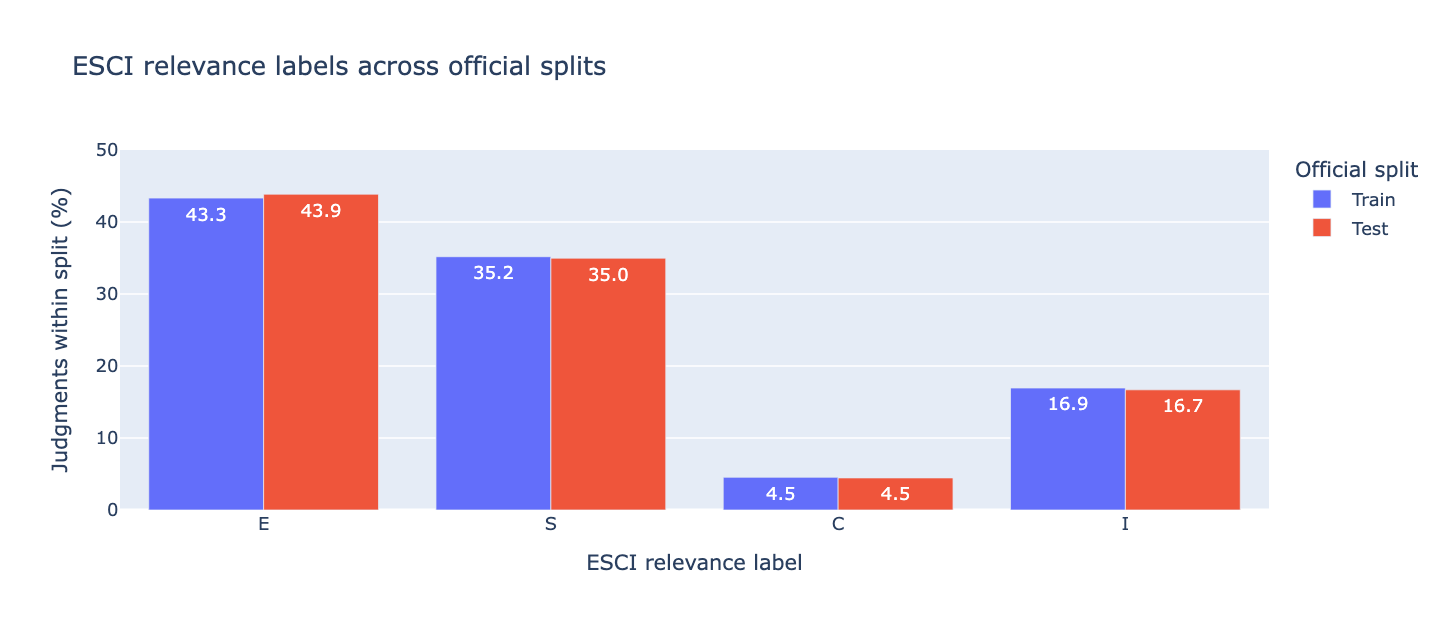

In [3]:
label_distribution = (
    judgments.group_by("split", "esci_label")
    .len(name="pairs")
    .with_columns(
        (100 * pl.col("pairs") / pl.col("pairs").sum().over("split")).alias("share_percent")
    )
    .sort("esci_label", "split", descending=[False, True])
)
display(label_distribution)

class_figure = px.bar(
    label_distribution,
    x="esci_label",
    y="share_percent",
    color="split",
    barmode="group",
    text_auto=".1f",
    category_orders={"esci_label": ["E", "S", "C", "I"], "split": ["Train", "Test"]},
    labels={
        "esci_label": "ESCI relevance label",
        "share_percent": "Judgments within split (%)",
        "split": "Official split",
    },
    title="ESCI relevance labels across official splits",
)
class_figure.update_yaxes(range=[0, 50])
kaleido.write_fig_sync(
    class_figure,
    path=figure_dir / "esci_class_balance.png",
    opts={"format": "png", "width": 960, "height": 420, "scale": 1.5},
    kopts={"mathjax": False},
)
display(Image(filename=str(figure_dir / "esci_class_balance.png"), width=960))

Exact and Substitute dominate both splits, while Complement accounts for about
4.5% of judgments. I see similar class proportions in train and test, although
this alone does not establish similar query difficulty. I report macro-F1 and
class supports alongside accuracy to make minority-class performance visible.

## 3. Product metadata completeness

I count null and whitespace-only fields across the unique product catalog.
Each product contributes once, regardless of how many query-product judgments
mention it.

field,missing_products,share_percent
str,u32,f64
"""Title""",0,0.0
"""Brand""",27191,5.640058
"""Bullet points""",63627,13.197747
"""Color""",155144,32.180542
"""Description""",230384,47.7871


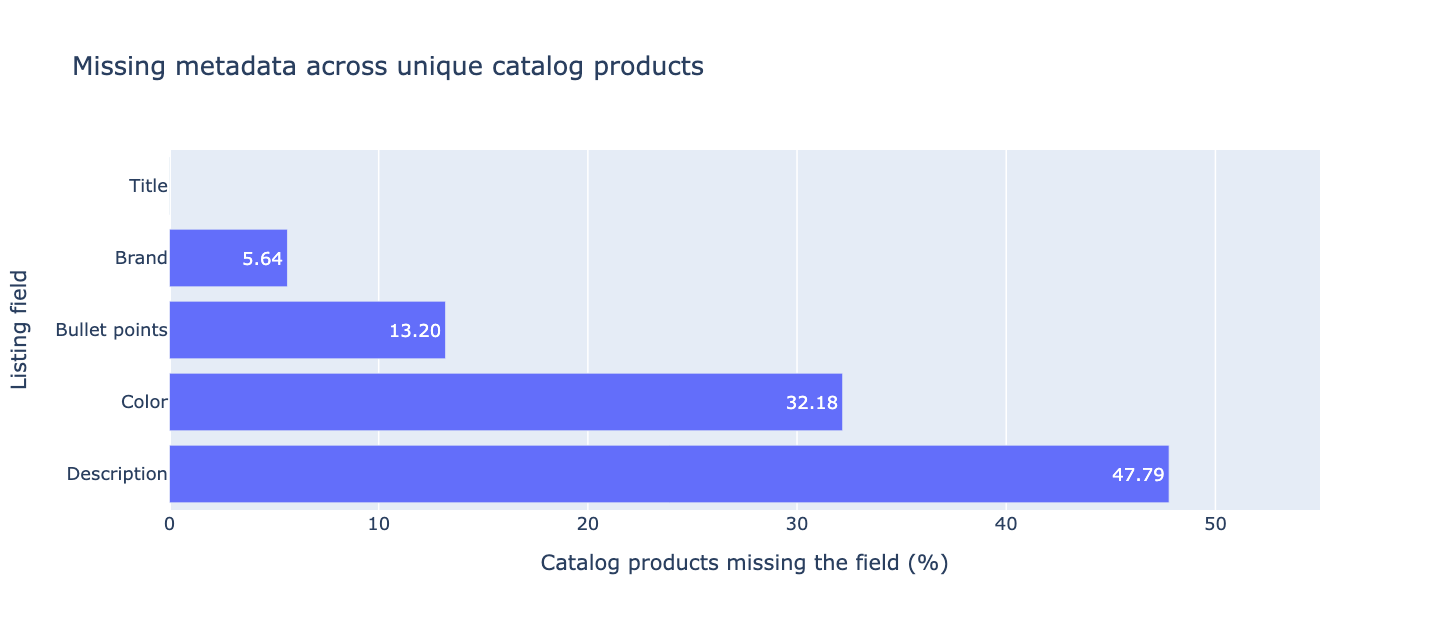

In [4]:
field_names = {
    "product_title": "Title",
    "product_brand": "Brand",
    "product_bullet_point": "Bullet points",
    "product_color": "Color",
    "product_description": "Description",
}
missing_metadata = (
    pl.scan_parquet(processed_dir / "catalog.parquet")
    .select(
        pl.len().alias("catalog_products"),
        *[
            (pl.col(name).is_null() | pl.col(name).str.strip_chars().eq("").fill_null(False))
            .sum()
            .alias(name)
            for name in field_names
        ],
    )
    .collect(engine="streaming")
    .unpivot(index="catalog_products", variable_name="field", value_name="missing_products")
    .with_columns(
        pl.col("field").replace_strict(field_names),
        (100 * pl.col("missing_products") / pl.col("catalog_products")).alias("share_percent"),
    )
)
if missing_metadata["catalog_products"][0] != manifest["catalog_products"]:
    raise ValueError("Catalog count differs from the prepared manifest")
display(missing_metadata.select("field", "missing_products", "share_percent"))

missing_figure = px.bar(
    missing_metadata,
    x="share_percent",
    y="field",
    orientation="h",
    text_auto=".2f",
    labels={"share_percent": "Catalog products missing the field (%)", "field": "Listing field"},
    title="Missing metadata across unique catalog products",
)
missing_figure.update_xaxes(range=[0, 55])
missing_figure.update_yaxes(
    categoryorder="array", categoryarray=list(field_names.values()), autorange="reversed"
)
missing_figure.write_image(
    figure_dir / "esci_missing_metadata.png", width=960, height=420, scale=1.5
)
display(Image(filename=str(figure_dir / "esci_missing_metadata.png"), width=960))

Every product has a title, but 47.79% lack descriptions and 32.18% lack color
metadata. I therefore use titles as the main retrieval field and retain brands
and bullet points where available. Missing attributes remain unknown, since
their absence does not establish product specifications.

## 4. Judged products per query

I count the judged products for every query in each split and summarize the
median, p95, and maximum. These counts describe the annotation pools. They do
not tell me how many relevant products exist across the full catalog.

split,queries,minimum,median,p95,maximum
str,u32,u32,f64,f64,u32
"""Train""",20888,8,16.0,40.0,188
"""Test""",8956,8,16.0,40.0,95


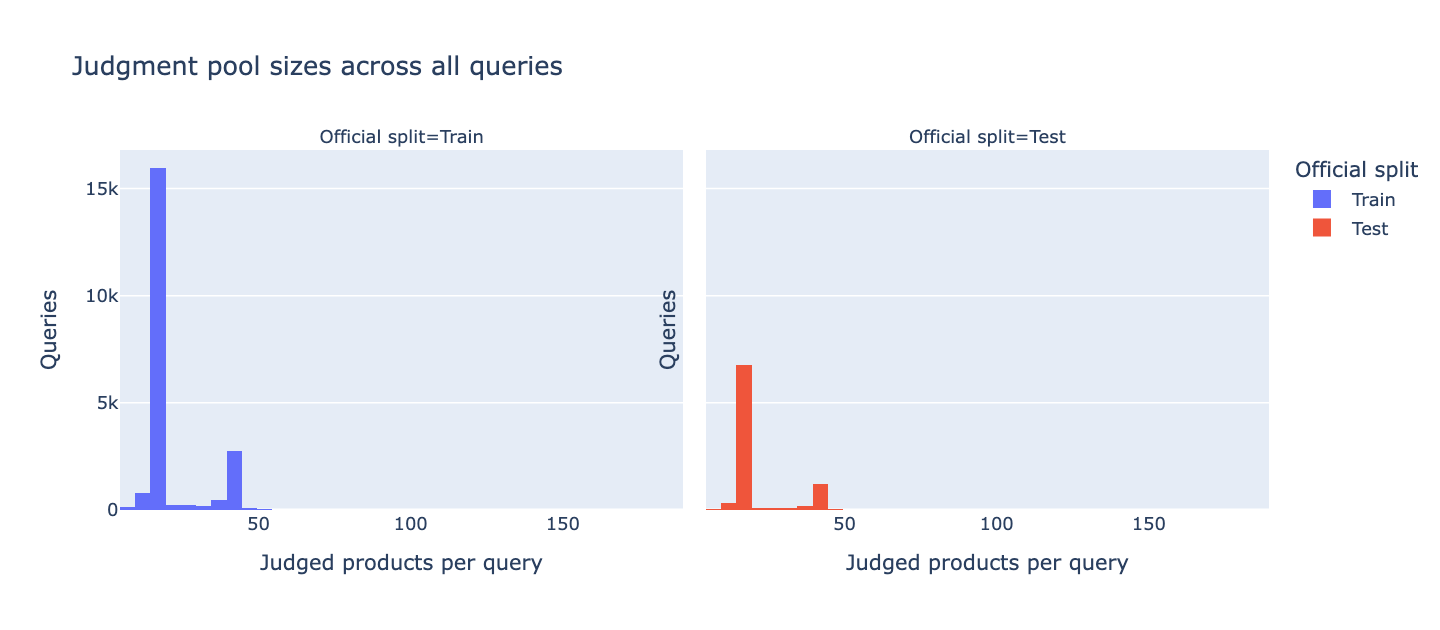

- **Train**: median 16, p95 40.0, maximum 188 judged products per query.
- **Test**: median 16, p95 40.0, maximum 95 judged products per query.

In [5]:
query_counts = judgments.group_by("split", "query_id").len(name="judged_products")
query_summary = (
    query_counts.group_by("split")
    .agg(
        pl.len().alias("queries"),
        pl.col("judged_products").min().alias("minimum"),
        pl.col("judged_products").median().alias("median"),
        pl.col("judged_products").quantile(0.95, interpolation="linear").alias("p95"),
        pl.col("judged_products").max().alias("maximum"),
    )
    .sort("split", descending=True)
)
display(query_summary)

query_figure = px.histogram(
    query_counts,
    x="judged_products",
    color="split",
    facet_col="split",
    nbins=50,
    category_orders={"split": ["Train", "Test"]},
    labels={"judged_products": "Judged products per query", "split": "Official split"},
    title="Judgment pool sizes across all queries",
)
query_figure.update_yaxes(title_text="Queries")
kaleido.write_fig_sync(
    query_figure,
    path=figure_dir / "esci_query_judgments.png",
    opts={"format": "png", "width": 960, "height": 420, "scale": 1.5},
    kopts={"mathjax": False},
)
display(Image(filename=str(figure_dir / "esci_query_judgments.png"), width=960))

query_findings = "\n".join(
    f"- **{record['split']}**: median {record['median']:.0f}, "
    f"p95 {record['p95']:.1f}, maximum {record['maximum']} judged products per query."
    for record in query_summary.iter_rows(named=True)
)
display(Markdown(query_findings))

Both splits have a median of 16 judged products per query and a p95 of 40.
The largest pools contain 188 products in train and 95 in test. I report both
macro and micro retrieval coverage because macro gives each eligible query
equal weight, while micro gives larger judged pools more weight.

## What I take from the analysis

I keep the official query splits and separate relevance labels from product
features. Complete titles provide a consistent retrieval input, while sparse
metadata limits how confidently I can assess detailed requirements. Class
imbalance makes per-class metrics important, particularly for Complement.

The listings are historical and relevance judgments are incomplete. I cannot
infer current prices, availability, or exhaustive catalog-wide recall from
these data. This analysis describes the dataset rather than measuring final
shopping-task success.